# Gradient Descent step by step

Example: predicting an apartment price (million centimes) from its area (m²).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from linear_regression import gradient_descent, cost, predict
%load_ext autoreload
%autoreload 2

## Data and starting point

We start with a guess: $\theta_0 = 0$ and $\theta_1 = 15$, and a small learning rate $\alpha = 0.0001$.

In [2]:
area = np.array([50, 65, 80, 95, 110])
price = np.array([900, 1100, 1500, 1600, 2000])

alphas = {
    0.00001: "alpha too small (slow)",
    0.0001: "alpha good (fast)",
    0.0003: "alpha too large (diverges)",
}

## Effect of the learning rate

I run gradient descent for 30 iterations with three values of alpha:
- 0.00001 (small)
- 0.0001 (medium)
- 0.0003 (large)

I plot the cost after each iteration (log scale).

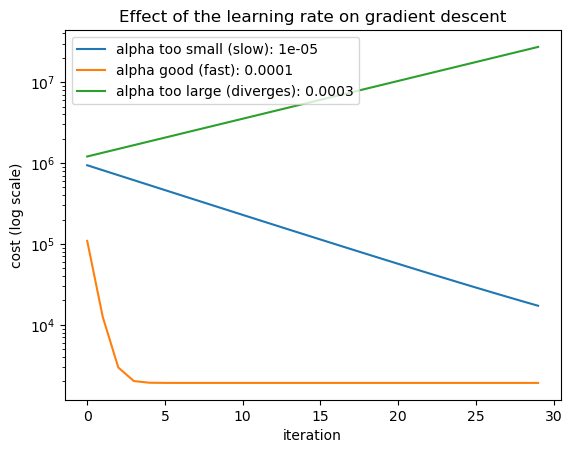

In [ ]:
for alpha, label in alphas.items():
    _, _, history = gradient_descent(area, price, alpha=alpha, n_iterations=30)
    plt.plot(history, label=f"{label}: {alpha}")

plt.yscale("log")
plt.xlabel("iteration")
plt.ylabel("cost (log scale)")
plt.title("Effect of the learning rate on gradient descent")
plt.legend()
plt.show()

## What I observe

- **Small alpha (0.00001):** the cost decreases slowly. After 30 iterations it is still high (about ___).
- **Medium alpha (0.0001):** the cost decreases fast. After about ___ iterations it stops changing (near 1913).
- **Large alpha (0.0003):** the cost increases. The algorithm does not converge.

## Conclusion

Alpha is the step size. If it is too small, learning is slow. If it is too large, the cost goes up. A value in the middle works best.

In [4]:
theta0, theta1 = 0.0, 15.0
alpha = 0.0001
n = len(area)

## One iteration = 5 steps

1. **Hypothesis**: $\hat{y} = \theta_0 + \theta_1 x$
2. **Errors**: $\hat{y} - y$
3. **Cost**: $J = \frac{1}{2N} \sum (\hat{y} - y)^2$
4. **Gradients**: $\frac{\partial J}{\partial \theta_0}$ and $\frac{\partial J}{\partial \theta_1}$
5. **Update**: $\theta := \theta - \alpha \frac{\partial J}{\partial \theta}$

In [6]:
for step in range(1, 4):
    y_hat = predict(theta0, theta1, area)       # step 1: hypothesis
    errors = y_hat - price                      # step 2: errors
    j = cost(theta0, theta1, area, price)       # step 3: cost
    grad0 = errors.sum() / n                    # step 4: gradients
    grad1 = (errors * area).sum() / n
    new_theta0 = theta0 - alpha * grad0         # step 5: update
    new_theta1 = theta1 - alpha * grad1
    
print(f"--- iteration {step} ---")
print("theta     :", theta0, theta1)
print("y_hat     :", y_hat)
print("errors    :", errors)
print("cost J    :", j)
print("gradients :", grad0, grad1)
print("new theta :", new_theta0, new_theta1)

theta0, theta1 = new_theta0, new_theta1

--- iteration 3 ---
theta     : 0.0 15.0
y_hat     : [ 750.  975. 1200. 1425. 1650.]
errors    : [-150. -125. -300. -175. -350.]
cost J    : 28125.0
gradients : -220.0 -18950.0
new theta : 0.022000000000000002 16.895


## What I observe

- The cost decreases at each iteration: 28125, then 4512.5, then 2170.9.
- Both gradients are negative, so theta0 and theta1 increase.
- The gradients get smaller at each iteration, so the steps get smaller.